# 실습 03 · Embedding·Cosine·시각화 (기본필수)

문장을 **벡터(숫자 묶음)** 로 바꾸면, 두 문장이 비슷한지를 **벡터의 방향**으로 비교할 수 있습니다. 그 비교 점수가 **Cosine Similarity**입니다.

### 사용 방법
1. **결과는 이미 셀 아래에 저장되어 있습니다.** 읽기만 해도 흐름을 따라갈 수 있어요.
2. 직접 돌려 보려면 `파일 → Drive에 사본 저장`으로 내 사본을 만드세요.
3. 맨 위 **⚙️ 준비 셀을 먼저 한 번 실행**한 뒤, 보고 싶은 구간의 셀을 실행하세요. 각 구간은 준비 셀만 있으면 따로 실행됩니다.
4. **✏️ 표시 셀**은 오른쪽 입력 칸·슬라이더의 값을 바꾸고 실행해 보세요. 코드의 숫자도 함께 바뀝니다.

| 구간 | 내용 |
|---|---|
| 0 | 실습 벡터 A/B/C 보기 |
| 1 | 그림으로 먼저 보기 |
| B01 | Cosine Similarity 계산 (공식을 한 단계씩) |
| B02 | 점수 해석하기 |
| B03 | 그래프와 결과 저장 (`main.py`와 같은 결과) |

> ⚠️ 여기 벡터는 PPT 33장의 **교육용 2D 예시**입니다. 실제 Embedding 모델은 수백~수천 차원의 벡터를 만듭니다.

In [1]:
#@title ⚙️ 먼저 실행하세요 — 실습 공통 코드 준비
# ── 원본: 20261113/mentor/01_basic/common/support.py (그대로 포함) ──
"""강의 공통 오프라인 계산 도구: 실제 사전학습 LLM이 아닙니다.

교육용 정규표현식 토큰화·작은 벡터·가중치 계산만 제공합니다.
Transformer의 tokenizer/embedding 품질을 이 도구로 평가할 수 없습니다.
"""
from pathlib import Path
import json
import math
import re
import torch

DATA = [
    {"id":"A", "title":"실습 파일 보관", "content":"실습 파일은 개인 폴더에 보관합니다.", "category":"learning"},
    {"id":"B", "title":"서버 실행", "content":"프로젝트 폴더에서 서버를 실행합니다.", "category":"environment"},
    {"id":"C", "title":"질문 작성", "content":"오류 메시지와 시도한 작업을 함께 적습니다.", "category":"learning"},
]
SPECIAL = ["[PAD]", "[UNK]", "[BOS]", "[EOS]"]

def words(text: str) -> list[str]:
    """교육용: 한글 연속 글자/영문/숫자/문장부호 분리. 서브워드 토크나이저가 아님."""
    return re.findall(r'[가-힣]+|[A-Za-z]+|\d+|[^\w\s]', text)

class ToyTokenizer:
    """BERT tokenizer 대체가 아닌, 오프라인 개념 확인용 규칙 기반 어휘표."""
    def __init__(self, corpus):
        wordset=sorted({word for line in corpus for word in words(line)})
        self.vocab={tok:i for i,tok in enumerate(SPECIAL + wordset)}
        self.reverse={i:t for t,i in self.vocab.items()}

    def encode(self, text: str, max_length=None, padding_to=None):
        raw=words(text)
        tokens=["[BOS]"]+raw+["[EOS]"]
        truncated=False
        if max_length is not None:
            if max_length<2: raise ValueError("BOS/EOS를 포함하려면 max_length>=2")
            if len(tokens)>max_length:
                tokens=tokens[:max_length-1]+["[EOS]"]
                truncated=True
        valid=len(tokens)
        if padding_to is not None:
            if padding_to<valid: raise ValueError("padding_to must be >= valid length")
            tokens=tokens+["[PAD]"]*(padding_to-valid)
        ids=[self.vocab.get(t,self.vocab["[UNK]"]) for t in tokens]
        mask=[0 if t=="[PAD]" else 1 for t in tokens]
        return {"tokens":tokens,"input_ids":ids,"attention_mask":mask,
                "valid_length":valid,"truncated":truncated,"original_length":len(raw)+2}

    def batch(self, texts, max_length=None):
        items=[self.encode(t,max_length=max_length) for t in texts]
        max_size=max(len(i["input_ids"]) for i in items)
        return [self.encode(t,max_length=max_length,padding_to=max_size) for t in texts]

def context_budget(window, parts:dict, output_reserved:int):
    used=sum(parts.values())
    return {"window":window,"input_used":used,"output_reserved":output_reserved,
            "remaining":window-used-output_reserved,
            "fits":used+output_reserved<=window}

def cosine(a,b):
    a=torch.as_tensor(a,dtype=torch.float32)
    b=torch.as_tensor(b,dtype=torch.float32)
    return float(torch.nn.functional.cosine_similarity(a,b,dim=0))

def attention(q,k,v,causal=True):
    q=torch.as_tensor(q,dtype=torch.float32)
    k=torch.as_tensor(k,dtype=torch.float32)
    v=torch.as_tensor(v,dtype=torch.float32)
    scores=q@k.T/math.sqrt(q.shape[-1])
    mask=torch.triu(torch.ones_like(scores,dtype=torch.bool),diagonal=1)
    weights=torch.softmax(scores.masked_fill(mask,float('-inf')) if causal else scores,dim=-1)
    return scores,weights,weights@v,mask

def write_json(path, data):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(json.dumps(data,ensure_ascii=False,indent=2),encoding='utf-8')

def write_md(path,text):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(text,encoding='utf-8')

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

# ── 노트북 전용 준비 ──
import pandas as pd
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(1)

# 실습 벡터 (PPT 33장, main.py와 같은 값)
coords = {"A": [1.0, 0.0], "B": [0.8, 0.2], "C": [-1.0, 0.0]}

def plot_vectors(vecs, title=""):
    """원점에서 출발하는 화살표로 벡터를 그림 (방향 비교용)"""
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    for i, (label, (x, y)) in enumerate(vecs.items()):
        ax.annotate("", xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color=f"C{i}", lw=2))
        ax.annotate(label, (x, y), xytext=(6, 6), textcoords="offset points",
                    color=f"C{i}", fontsize=13, weight="bold")
    lim = max(1.2, 1.2 * max(abs(v) for xy in vecs.values() for v in xy))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.axhline(0, lw=.6, color="gray"); ax.axvline(0, lw=.6, color="gray"); ax.grid(alpha=.2)
    ax.set_title(title)
    plt.show()

def angle_deg(cos_value):
    """코사인 값 → 두 벡터 사이 각도(도)"""
    return math.degrees(math.acos(max(-1.0, min(1.0, cos_value))))

print("준비 완료 ✅  벡터:", coords)

준비 완료 ✅  벡터: {'A': [1.0, 0.0], 'B': [0.8, 0.2], 'C': [-1.0, 0.0]}


## 0. 실습 벡터 보기
A, B, C 세 문장을 2차원 벡터로 나타냈다고 가정합니다. 숫자 2개(x1, x2)가 문장 하나입니다.

In [2]:
pd.DataFrame(coords, index=["x1", "x2"]).T

,x1,x2
A,1.0,0.0
B,0.8,0.2
C,-1.0,0.0


In [3]:
matrix = torch.tensor(list(coords.values()), dtype=torch.float32)
print("벡터 하나의 shape:", list(matrix[0].shape), " ← 숫자 2개")
print("전체 행렬 shape  :", list(matrix.shape), " ← 문장 3개 × 숫자 2개")
matrix

벡터 하나의 shape: [2]  ← 숫자 2개
전체 행렬 shape  : [3, 2]  ← 문장 3개 × 숫자 2개


tensor([[ 1.0000,  0.0000],
        [ 0.8000,  0.2000],
        [-1.0000,  0.0000]])

## 1. 그림으로 먼저 보기
원점에서 각 벡터 끝까지 화살표를 그리면 **방향**이 보입니다.
- A와 B는 거의 **같은 방향**
- A와 C는 정확히 **반대 방향**

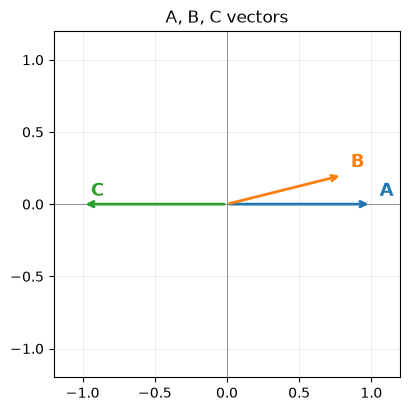

In [4]:
plot_vectors(coords, "A, B, C vectors")

## B01. Cosine Similarity 계산

두 벡터 사이 **각도의 코사인 값**입니다.

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \times \|b\|}$$

- 분자 `a · b` (내적): 같은 위치의 숫자끼리 곱해서 더한 값
- 분모 `‖a‖ × ‖b‖`: 두 벡터 길이의 곱 → **길이의 영향을 없애고 방향만** 비교

### B01-1. A와 B를 한 단계씩 계산

In [5]:
a = torch.tensor(coords["A"])
b = torch.tensor(coords["B"])
a, b

(tensor([1., 0.]), tensor([0.8000, 0.2000]))

In [6]:
dot = (a * b).sum()          # 1.0×0.8 + 0.0×0.2
print("곱한 값:", (a * b).tolist())
print("내적 a·b:", dot.item())

곱한 값: [0.800000011920929, 0.0]
내적 a·b: 0.800000011920929


In [7]:
norm_a = a.norm()            # √(1.0² + 0.0²)
norm_b = b.norm()            # √(0.8² + 0.2²)
print("‖a‖ =", round(norm_a.item(), 4))
print("‖b‖ =", round(norm_b.item(), 4))

‖a‖ = 1.0
‖b‖ = 0.8246


In [8]:
manual = (dot / (norm_a * norm_b)).item()
print(f"직접 계산: {dot.item():.4f} / ({norm_a.item():.4f} × {norm_b.item():.4f}) = {manual:.4f}")

직접 계산: 0.8000 / (1.0000 × 0.8246) = 0.9701


### B01-2. 공통 함수 `cosine()`으로 계산 (`main.py`와 같은 코드)

In [9]:
s_ab = cosine(coords["A"], coords["B"])
s_ac = cosine(coords["A"], coords["C"])
print(f"cos(A, B) = {s_ab:.4f}   각도 {angle_deg(s_ab):.1f}°")
print(f"cos(A, C) = {s_ac:.4f}   각도 {angle_deg(s_ac):.1f}°")

cos(A, B) = 0.9701   각도 14.0°
cos(A, C) = -1.0000   각도 180.0°


In [10]:
assert abs(s_ab - 0.9701) < 1e-4 and s_ac == -1.0
assert abs(s_ab - manual) < 1e-6     # 직접 계산과 함수 결과가 같은지
print("B01 통과 ✅")

B01 통과 ✅


### B01-3. 모든 쌍을 한 번에 보기
대각선은 자기 자신과의 비교라 항상 1입니다.

In [11]:
sim = F.cosine_similarity(matrix.unsqueeze(1), matrix.unsqueeze(0), dim=-1)
pd.DataFrame(sim.numpy(), index=coords, columns=coords).round(4)

,A,B,C
A,1.0000,0.9701,-1.0000
B,0.9701,1.0000,-0.9701
C,-1.0000,-0.9701,1.0000


### B01-4. 길이는 상관없다
B를 10배로 늘려도 방향은 그대로라 코사인 값은 같습니다. Embedding 비교에서 **문장 길이에 덜 흔들리는** 이유입니다.

In [12]:
b_long = [x * 10 for x in coords["B"]]
print("B      :", coords["B"], "→ cos =", round(cosine(coords["A"], coords["B"]), 4))
print("B × 10 :", b_long, "→ cos =", round(cosine(coords["A"], b_long), 4))

B      : [0.8, 0.2] → cos = 0.9701
B × 10 : [8.0, 2.0] → cos = 0.9701


### ✏️ B01 직접 해 보기 — B를 움직여 보세요

B = [0.8, 0.2]  →  cos(A, B) = 0.9701   각도 14.0°


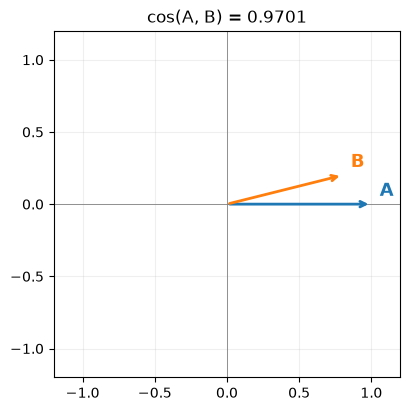

In [13]:
#@title ✏️ B 벡터의 좌표를 바꿔 보세요
bx = 0.8  #@param {type:"slider", min:-1, max:1, step:0.1}
by = 0.2  #@param {type:"slider", min:-1, max:1, step:0.1}

my_b = [bx, by]
s = cosine(coords["A"], my_b)
print(f"B = {my_b}  →  cos(A, B) = {s:.4f}   각도 {angle_deg(s):.1f}°")
plot_vectors({"A": coords["A"], "B": my_b}, f"cos(A, B) = {s:.4f}")

## B02. 점수 해석하기

| 코사인 값 | 각도 | 의미 |
|---|---|---|
| 1 | 0° | 같은 방향 (매우 비슷) |
| 0 | 90° | 관계없음 |
| -1 | 180° | 반대 방향 |

`main.py`는 0.9보다 크면 "비슷함", -0.99보다 작으면 "반대 방향"으로 판정합니다.

In [14]:
interpretation = {"A_B": "방향이 비슷함" if s_ab > 0.9 else "차이 있음",
                  "A_C": "반대 방향" if s_ac < -0.99 else "차이 있음",
                  "note": "코사인이 높다는 사실만으로 RAG 답변의 사실성을 보장하지 않는다"}
interpretation

{'A_B': '방향이 비슷함',
 'A_C': '반대 방향',
 'note': '코사인이 높다는 사실만으로 RAG 답변의 사실성을 보장하지 않는다'}

> **주의:** 코사인이 높다는 건 "벡터 방향이 비슷하다"는 뜻일 뿐입니다. 검색된 문서가 **사실인지**는 따로 확인해야 합니다. (11/18 Vector DB, 11/20 RAG에서 이어집니다)

In [15]:
#@title ✏️ 판정 기준을 바꿔 보세요
similar_threshold = 0.9  #@param {type:"slider", min:0, max:1, step:0.05}

for pair, value in [("A-B", s_ab), ("A-C", s_ac)]:
    verdict = "비슷함" if value > similar_threshold else "비슷하지 않음"
    print(f"{pair}: {value:.4f} → {verdict}")

A-B: 0.9701 → 비슷함
A-C: -1.0000 → 비슷하지 않음


## B03. 그래프와 결과 저장 (`main.py`와 같은 결과)
`main.py`와 같은 점 그래프를 그려 `outputs/vectors.png`로 저장하고, 결과를 `outputs/cosine_report.json`으로 저장합니다. 이 셀은 준비 셀만 있으면 혼자 실행됩니다.

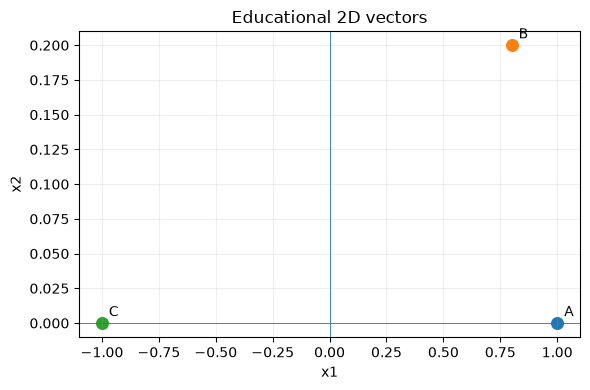

[03] AB=0.9701 AC=-1.0000, shape=[3, 2]


In [16]:
s_ab = cosine(coords["A"], coords["B"])
s_ac = cosine(coords["A"], coords["C"])
interpretation = {"A_B": "방향이 비슷함" if s_ab > 0.9 else "차이 있음",
                  "A_C": "반대 방향" if s_ac < -0.99 else "차이 있음",
                  "note": "코사인이 높다는 사실만으로 RAG 답변의 사실성을 보장하지 않는다"}
matrix = torch.tensor(list(coords.values()), dtype=torch.float32)
shapes = {"vector": list(matrix[0].shape), "matrix": list(matrix.shape)}

fig, ax = plt.subplots(figsize=(6, 4))
for label, (x, y) in coords.items():
    ax.scatter(x, y, s=70); ax.annotate(label, (x, y), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="x1", ylabel="x2", title="Educational 2D vectors")
ax.axhline(0, lw=.6); ax.axvline(0, lw=.6); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT_DIR / "vectors.png", dpi=125)
plt.show()

write_json(OUT_DIR / "cosine_report.json", {
    "vectors": coords, "cosine": {"AB": s_ab, "AC": s_ac},
    "interpretation": interpretation, "ranked": [], "shapes": shapes,
    "token_shape": [], "pooled_shape": [],
    "limitations": ["이 숫자는 예시 벡터이며 문장 의미 품질을 증명하지 않는다"],
})
print(f"[03] AB={s_ab:.4f} AC={s_ac:.4f}, shape={shapes['matrix']}")

In [17]:
#@title 📥 결과 파일 내려받기 (Colab)
if IN_COLAB:
    from google.colab import files
    for name in ['vectors.png', 'cosine_report.json']:
        files.download(str(OUT_DIR / name))
else:
    print("Colab에서 실행하면 결과 파일이 내려받아집니다:", ['vectors.png', 'cosine_report.json'])

Colab에서 실행하면 결과 파일이 내려받아집니다: ['vectors.png', 'cosine_report.json']


---
### 정리
- **Embedding**은 문장을 벡터로 바꾼 것이고, 비슷한 문장일수록 벡터 **방향**이 비슷하다.
- **Cosine Similarity** = 내적 ÷ (길이 × 길이). 길이와 상관없이 방향만 비교한다. 범위는 -1 ~ 1.
- A-B ≈ **0.9701** (거의 같은 방향), A-C = **-1** (반대 방향).
- 코사인이 높아도 **사실성은 보장하지 않는다** → 검증은 따로 필요하다.